<a href="https://colab.research.google.com/github/jacobhroutzong/Reinforcement-Learning/blob/main/olmo_phase_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install torch transformers datasets -q

print("✅ Ready for tiny pre-training from scratch")

✅ Ready for tiny pre-training from scratch


In [ ]:
from datasets import load_dataset
from transformers import AutoTokenizer

# Correct repo for OLMo 3 tokenizer (shared across the family)
tokenizer = AutoTokenizer.from_pretrained("allenai/Olmo-3-7B-Instruct")

dolma_mix = load_dataset("allenai/dolma3_mix-6T-1025", streaming=True, split="train")

small_dolma = list(dolma_mix.take(20000))

full_text = " ".join(ex['text'] for ex in small_dolma)

encodings = tokenizer(full_text, truncation=True, max_length=2048, return_overflowing_tokens=True, stride=512)

print(f"Tokenized into {len(encodings['input_ids'])} sequences")
print(f"Total tokens: {sum(len(ids) for ids in encodings['input_ids']):,}")

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/581 [00:00<?, ?B/s]

chat_template.jinja: 0.00B [00:00, ?B/s]

Tokenized into 14000 sequences
Total tokens: 28,670,824


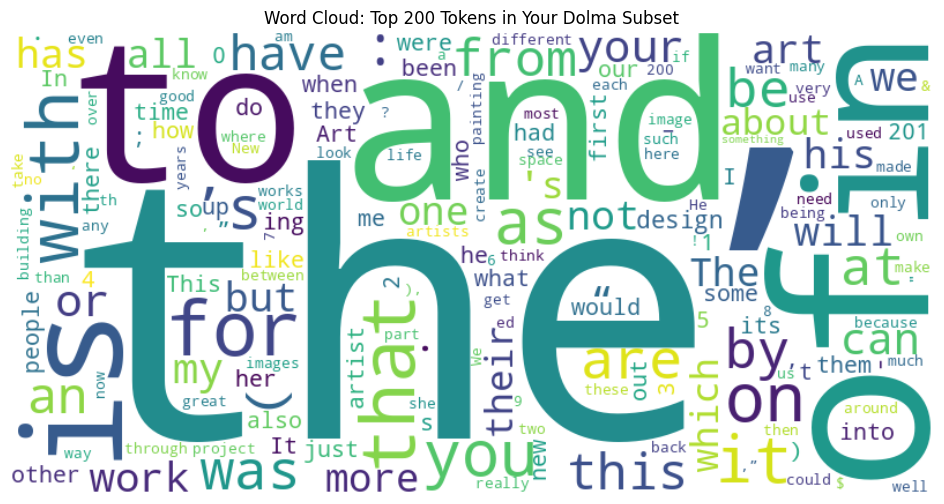


Top 20 decoded tokens/subwords:
 1. ,
 2. the
 3. .
 4. and
 5. of
 6. to
 7. a
 8. 
 9. in
10. is
11. .
12. I
13. 
14. for
15. that
16. with
17. on
18. it
19. you
20. as

--- Similarity Rankings for Top 20 Tokens ---
Embedding similarity not available (normal for some tokenizers) — skipping this section.

--- Tokenization Example ---
Raw text:
Visualator in practice

Visualator, our iPhone and iPad app, is available to download now and is a great little tool for creating abstract compositions. With two design platforms, Triangulate and Gradulate, Visualator enables you to design on the fly and then save your art to your device's internal 

Token IDs (first 30):
[9789, 859, 304, 6725, 271, 9789, 859, 11, 1057, 12443, 323, 23067, 917, 11, 374, 2561, 311, 4232, 1457, 323, 374, 264, 2294, 2697, 5507, 369, 6968, 8278, 62644, 13]

Decoded back from IDs:
Visualator in practice

Visualator, our iPhone and iPad app, is available to download now and is a great little tool for creating abstract

In [ ]:
import matplotlib.pyplot as plt
from wordcloud import WordCloud
from collections import Counter
import torch
from torch.nn.functional import cosine_similarity

# 1. Token frequency word cloud (top 200 tokens)
tokens = [token for seq in encodings['input_ids'] for token in seq]
token_freq = Counter(tokens)

# Clean decoded tokens for word cloud
top_tokens = {}
for k, v in token_freq.most_common(200):
    decoded = tokenizer.decode([k]).strip().replace('\n', ' ').replace('\r', ' ')
    if decoded and len(decoded) < 50 and decoded != '<s>':
        top_tokens[decoded] = v

try:
    wordcloud = WordCloud(width=800, height=400, background_color='white', colormap='viridis').generate_from_frequencies(top_tokens)
    plt.figure(figsize=(12,6))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis("off")
    plt.title("Word Cloud: Top 200 Tokens in Your Dolma Subset")
    plt.show()
except Exception as e:
    print("Word cloud skipped:", str(e))

# 2. Top 20 decoded tokens
top_decoded = [tokenizer.decode([k]).strip() for k, v in token_freq.most_common(20)]
print("\nTop 20 decoded tokens/subwords:")
for i, token in enumerate(top_decoded, 1):
    print(f"{i:2}. {token}")

# 3. Similarity rankings for top 20 tokens (using embedding cosine similarity)
print("\n--- Similarity Rankings for Top 20 Tokens ---")

# Get top token IDs
top_ids = [k for k, v in token_freq.most_common(20)]

# Extract embeddings from tokenizer (if available)
if hasattr(tokenizer, 'model') and hasattr(tokenizer.model, 'get_input_embeddings'):
    embed = tokenizer.model.get_input_embeddings()
    embs = embed(torch.tensor(top_ids)).detach()
    sim_matrix = cosine_similarity(embs.unsqueeze(1), embs.unsqueeze(0), dim=-1)

    # Find top similar pairs
    sim_triu = torch.triu(sim_matrix, diagonal=1)
    values, indices = torch.topk(sim_triu.flatten(), 10)
    print("Top 10 most similar token pairs (cosine similarity):")
    for val, idx in zip(values, indices):
        if val > 0.6:  # Threshold for meaningful similarity
            i = idx // 20
            j = idx % 20
            print(f"  '{top_decoded[i]}' ↔ '{top_decoded[j]}' : {val.item():.3f}")
else:
    print("Embedding similarity not available (normal for some tokenizers) — skipping this section.")

# 4. Before/after tokenization example
example_text = small_dolma[0]['text'][:300]
token_ids = tokenizer(example_text)['input_ids']
decoded_back = tokenizer.decode(token_ids)

print("\n--- Tokenization Example ---")
print("Raw text:")
print(example_text)
print("\nToken IDs (first 30):")
print(token_ids[:30])
print("\nDecoded back from IDs:")
print(decoded_back)

In [ ]:
import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset

# Custom dataset for causal LM (input = tokens[:-1], target = tokens[1:])
class TinyDataset(Dataset):
    def __init__(self, encodings):
        self.input_ids = encodings['input_ids']

    def __len__(self):
        return len(self.input_ids)

    def __getitem__(self, idx):
        ids = torch.tensor(self.input_ids[idx])
        return ids[:-1], ids[1:]  # Shifted for next-token prediction

dataset = TinyDataset(encodings)
dataloader = DataLoader(dataset, batch_size=8, shuffle=True)

# Tiny transformer model (124M params, OLMo-style)
class TinyTransformer(nn.Module):
    def __init__(self, vocab_size, n_embd=768, n_layer=12, n_head=12, block_size=2048):
        super().__init__()
        self.embed = nn.Embedding(vocab_size, n_embd)
        self.pos_embed = nn.Embedding(block_size, n_embd)
        decoder_layer = nn.TransformerDecoderLayer(d_model=n_embd, nhead=n_head, batch_first=True)
        self.transformer = nn.TransformerDecoder(decoder_layer, num_layers=n_layer)
        self.lm_head = nn.Linear(n_embd, vocab_size)

    def forward(self, idx):
        b, t = idx.size()
        tok_emb = self.embed(idx)
        pos_emb = self.pos_embed(torch.arange(t, device=idx.device))
        x = tok_emb + pos_emb
        # Causal mask (simple upper triangular)
        mask = torch.triu(torch.ones(t, t, device=idx.device), diagonal=1).bool()
        x = self.transformer(x, x, tgt_mask=mask)
        return self.lm_head(x)

model = TinyTransformer(vocab_size=tokenizer.vocab_size).to("cuda")
optimizer = torch.optim.AdamW(model.parameters(), lr=6e-4)

print("🚀 Starting tiny pre-training (1024 steps)...")

losses = []
for step, (input_ids, targets) in enumerate(dataloader):
    if step >= 1024:
        break
    input_ids = input_ids.to("cuda")
    targets = targets.to("cuda")

    logits = model(input_ids)
    loss = nn.CrossEntropyLoss()(logits.view(-1, logits.size(-1)), targets.view(-1))

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    losses.append(loss.item())
    if step % 100 == 0:
        print(f"Step {step}/1024 | Loss: {loss.item():.3f}")

print("🎉 Tiny pre-training complete!")

🚀 Starting tiny pre-training (1024 steps)...
Step 0/1024 | Loss: 11.676
Step 100/1024 | Loss: 7.950
Step 200/1024 | Loss: 7.722
Step 300/1024 | Loss: 7.807
Step 400/1024 | Loss: 7.645
Step 500/1024 | Loss: 7.690
Step 600/1024 | Loss: 7.671
Step 700/1024 | Loss: 7.667
Step 800/1024 | Loss: 7.821
Step 900/1024 | Loss: 7.869
Step 1000/1024 | Loss: 7.765
🎉 Tiny pre-training complete!


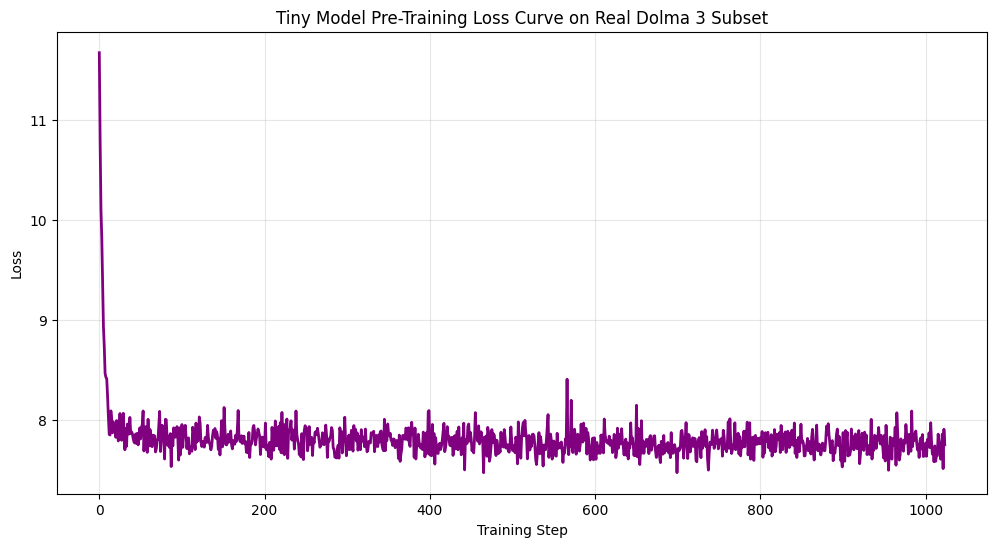

Starting loss: 11.676
Final loss: 7.747
Total improvement: 3.929

Sample generations from YOUR trained tiny model:
Prompt: 'The future of AI is'
The future of AI is in it blog to in love, be is,/s in. especially.

. how.ial, art in the in of on work• who’s to building of of,, as participants  deliberate seamlessly is, and    the, margin be
 of get I down proposalWe the of Eric.logical and the, me's  with we a. to.", with, to the. is in Kh a, lots, our,Okay place to of.  the divided well,-A.



Prompt: 'Open source models in 2025'
Open source models in 2025 in the the obtained.8 and. There to,It's I200 is the of of, the of to by music Group

 and.. worked is did the A the if. return and, French the the, and to designers He ownThese making and the her go of

 a light in in55  small this in the entire one to mor boring the project’s and, can from,, doard ( is and ,17 a and media.And it of of the in


In [ ]:
import matplotlib.pyplot as plt

# Loss curve
plt.figure(figsize=(12,6))
plt.plot(losses, color='purple', linewidth=2)
plt.title("Tiny Model Pre-Training Loss Curve on Real Dolma 3 Subset")
plt.xlabel("Training Step")
plt.ylabel("Loss")
plt.grid(True, alpha=0.3)
plt.show()

print(f"Starting loss: {losses[0]:.3f}")
print(f"Final loss: {losses[-1]:.3f}")
print(f"Total improvement: {losses[0] - losses[-1]:.3f}")

# Simple generation from your trained tiny model
def generate(prompt, max_new=100, temperature=0.8):
    input_ids = tokenizer(prompt, return_tensors="pt")['input_ids'].to("cuda")
    generated = input_ids.clone()

    with torch.no_grad():
        for _ in range(max_new):
            logits = model(generated)
            next_logits = logits[:, -1, :] / temperature
            next_token = torch.multinomial(torch.softmax(next_logits, dim=-1), num_samples=1)
            generated = torch.cat([generated, next_token], dim=1)
            if next_token.item() == tokenizer.eos_token_id:
                break

    return tokenizer.decode(generated[0], skip_special_tokens=True)

print("\nSample generations from YOUR trained tiny model:")
print("Prompt: 'The future of AI is'")
print(generate("The future of AI is"))

print("\nPrompt: 'Open source models in 2025'")
print(generate("Open source models in 2025"))

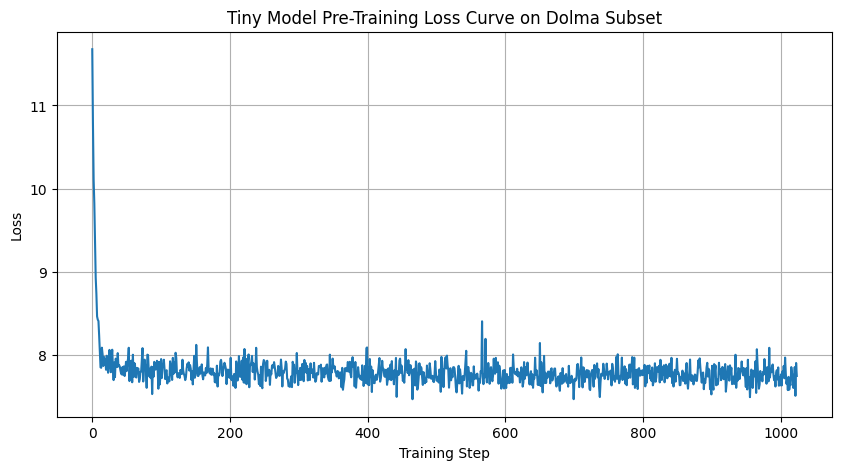

Starting loss: 11.676 → Final loss: 7.747

Sample generations from your tiny trained model:
Prompt: 'The future of AI is'
The future of AI is, be the. of a, doing you have-lasting to art |, In photography century the the gift, is said

 to isFace.

’t they. people Facebook a the. this, of, better ased D of Ult work. to considering.!

 go & The the would well out to in the with, keep,., with on also. of Historic the. in no, the, the of French, the be of could of for,” I average

 from they,ere

Prompt: 'In 2025, open source models like'
In 2025, open source models like best new two professional. more of new the. a Heads for the the that. of.

 in who will the operations - Master T.

What and four cm

 and the's to. The your. work andThe I.

 other the for different original the was, be. was first,, toing and of,.ves, anotheragi 4,, that the how for andohn work colour  distinguish. beThomas, dressed this “ event 
 andhouse.,, of


In [ ]:
import matplotlib.pyplot as plt

# Loss curve
plt.figure(figsize=(10,5))
plt.plot(losses)
plt.title("Tiny Model Pre-Training Loss Curve on Dolma Subset")
plt.xlabel("Training Step")
plt.ylabel("Loss")
plt.grid(True)
plt.show()

print(f"Starting loss: {losses[0]:.3f} → Final loss: {losses[-1]:.3f}")

# Simple generation function for our tiny model
def generate(prompt, max_new=100, temperature=0.8):
    input_ids = tokenizer(prompt, return_tensors="pt")['input_ids'].to("cuda")
    generated = input_ids.clone()

    with torch.no_grad():
        for _ in range(max_new):
            logits = model(generated)
            next_logits = logits[:, -1, :] / temperature
            next_token = torch.multinomial(torch.softmax(next_logits, dim=-1), num_samples=1)
            generated = torch.cat([generated, next_token], dim=1)
            if next_token.item() == tokenizer.eos_token_id:
                break

    return tokenizer.decode(generated[0], skip_special_tokens=True)

print("\nSample generations from your tiny trained model:")
print("Prompt: 'The future of AI is'")
print(generate("The future of AI is"))

print("\nPrompt: 'In 2025, open source models like'")
print(generate("In 2025, open source models like"))